# Evaluating Semantic Role Labeling Models using Challenge-Based Testing

Find the models to download at:

Logreg [here](https://drive.google.com/drive/folders/1AGpUh4PpvRzUHPMHsqk2bCkXL6XiA-PX?usp=sharing)

BERT [here](https://drive.google.com/file/d/105mzowiYDuIuEgkLe7M8dKgWl4NgXaw_/view?usp=sharing)

Please place them in the same folder as the notebook

## Imports

In [1]:
import adv_utils
from tqdm import tqdm
import time
import pandas as pd
import csv
import spacy
from spacy.tokens import Doc
from spacy import displacy
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
import pickle
import networkx as nx
from nltk.tree import Tree
import os
import logging
import numpy as np
import re
from collections import Counter
from datasets import load_dataset
from datasets import Sequence, ClassLabel, Features, Value
from evaluate import load
from datasets import Dataset
import torch
from transformers import AutoTokenizer, AutoModelForTokenClassification, TrainingArguments, Trainer, set_seed
import random
import json

E:\Software\Anaconda\Lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'en_core_web_md' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.4). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)
E:\Software\Anaconda\Lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'en_core_web_md' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.4). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [2]:
nlp = spacy.load("en_core_web_md")

sorted_unique_labels = ['ARG0', 'ARG1', 'ARG1-DSP', 'ARG2', 'ARG3', 'ARG4', 'ARG5', 'ARGA', 'ARGM-ADJ', 'ARGM-ADV', 'ARGM-CAU', 'ARGM-COM', 'ARGM-CXN', 'ARGM-DIR', 'ARGM-DIS', 'ARGM-EXT', 'ARGM-GOL', 'ARGM-LOC', 'ARGM-LVB', 'ARGM-MNR', 'ARGM-MOD', 'ARGM-NEG', 'ARGM-PRD', 'ARGM-PRP', 'ARGM-PRR', 'ARGM-REC', 'ARGM-TMP', 'C-ARG0', 'C-ARG1', 'C-ARG1-DSP', 'C-ARG2',
                        'C-ARG3', 'C-ARG4', 'C-ARGM-ADV', 'C-ARGM-COM', 'C-ARGM-CXN', 'C-ARGM-DIR', 'C-ARGM-EXT', 'C-ARGM-GOL', 'C-ARGM-LOC', 'C-ARGM-MNR', 'C-ARGM-PRP', 'C-ARGM-PRR', 'C-ARGM-TMP', 'C-V', 'R-ARG0', 'R-ARG1', 'R-ARG2', 'R-ARG3', 'R-ARG4', 'R-ARGM-ADJ', 'R-ARGM-ADV', 'R-ARGM-CAU', 'R-ARGM-COM', 'R-ARGM-DIR', 'R-ARGM-GOL', 'R-ARGM-LOC', 'R-ARGM-MNR', 'R-ARGM-TMP', '_']

##  Loading Models locally

In [3]:
loaded_logreg_model = pickle.load(open('./A1/model.pkl', 'rb'))
loaded_vectorizer = pickle.load(open('./A1/vec.pkl', 'rb'))
loaded_encoder = pickle.load(open('./A1/label_encoder.pkl', 'rb'))


model = AutoModelForTokenClassification.from_pretrained(
    "./A2/Matt_model/BERTModel")
tokenizer = AutoTokenizer.from_pretrained("./A2/Matt_model/Tokenizer")

E:\Software\Anaconda\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
E:\Software\Anaconda\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator DictVectorizer from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
E:\Software\Anaconda\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.5.1 when using version 1.5.2. This might lead to breaking code or i

## Main Predictor

In [4]:
def get_logreg_bert_predictions_df(
    json_file, loaded_logreg_model, loaded_vectorizer, loaded_encoder, tokenizer, model, sorted_unique_labels
):
    """
    Generates a DataFrame of SRL predictions from both logistic regression and BERT models
    for each sentence in a challenge dataset formatted in JSON.

    Each row corresponds to a single token in a sentence, including its gold label and predictions
    from both models. The capability each sentence tests is also included.

    Args:
        json_file (str): Path to the JSON file containing the challenge dataset.
        loaded_logreg_model: Pretrained logistic regression model.
        loaded_vectorizer: Vectorizer used for the logistic regression model.
        loaded_encoder: Label encoder used to decode model predictions.
        tokenizer: HuggingFace tokenizer for the BERT model.
        model: Pretrained transformer model for SRL.
        sorted_unique_labels (list): List of unique SRL labels (unused here but may be used elsewhere).

    Returns:
        pd.DataFrame: A DataFrame with one row per token, including sentence index,
                      capability, token, model predictions, and gold label.
    """
    import json
    import pandas as pd

    with open(json_file, "r") as infile:
        capability_blocks = json.load(infile)

    all_rows = []
    sentence_idx = 1

    for capability in capability_blocks:
        cap_name = capability['Capability']
        for sentence in capability['Sentences']:
            tokens = sentence['sentence_tok']
            gold_labels = sentence['gold']

            predictions_on_standalone_logreg = adv_utils.stand_alone_sent_logreg(
                tokens, sentence['predicate'], loaded_logreg_model, loaded_vectorizer, loaded_encoder
            )

            predictions_on_standalone_bert = adv_utils.stand_alone_sent_bert(
                tokens, sentence['predicate'], model, tokenizer
            )

            for idx, (token, logreg_prediction, bert_prediction, gold_label) in enumerate(
                zip(tokens, predictions_on_standalone_logreg,
                    predictions_on_standalone_bert, gold_labels)
            ):
                all_rows.append([
                    f'{sentence_idx}',
                    cap_name,
                    token.replace(
                        '[PRED]', '') if '[PRED]' in token else token,
                    logreg_prediction,
                    bert_prediction,
                    gold_label
                ])

            sentence_idx += 1

    df_predictions = pd.DataFrame(
        all_rows,
        columns=['Sentence_idx', 'Capability', 'Token', 'LogReg Prediction',
                 'BERT Prediction', 'Gold Label']
    )

    return df_predictions

## Arrange dataset

In [5]:
file_paths = [
    "ARG0_clefted_sentences.json",
    "ARG1_dative_alternations_full.json",
    "ARG2_dative_alternations_full.json",
    "ARG0_control_verbs_embedded.json",
    "ARG1_passive_constructions.json"
]

combined_data = []
for file_path in file_paths:
    with open('./json_files/' + file_path, "r") as f:
        data = json.load(f)
        combined_data.extend(data)

output_file = "combined_srl_challenge_dataset.json"
with open(output_file, "w") as f:
    json.dump(combined_data, f, indent=4)

print(f"Combined file saved as {output_file}")

Combined file saved as combined_srl_challenge_dataset.json


## Manage Predictions

In [6]:
predictions = get_logreg_bert_predictions_df(
    "./combined_srl_challenge_dataset.json", loaded_logreg_model, loaded_vectorizer, loaded_encoder, tokenizer, model, sorted_unique_labels
)

predictions.to_csv("final_data.csv", index=False)

E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


... (140 outputs left out)

E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


E:\Vrije_University\Courses\AdvancedNLP\Take home exam\adv_utils.py:373: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  BERTtrainer = Trainer(model=BERTmodel, tokenizer=BERTtokenizer)


## Failure Rate

In [7]:
df = pd.read_csv("final_data.csv")
df.columns = [col.strip() for col in df.columns]


def compute_failure_rate(group, model_column):
    """
    Computes the failure rate for a given model within a group of SRL predictions.
    Only considers tokens with a gold label other than "_".

    Args:
        group (DataFrame): A subset of the full DataFrame grouped by capability.
        model_column (str): The name of the column containing model predictions.

    Returns:
        float: The failure rate (proportion of incorrect predictions).
    """
    filtered = group[group["Gold Label"] != "_"]
    total = len(filtered)
    if total == 0:
        return 0.0
    failures = sum(filtered[model_column] != filtered["Gold Label"])
    return failures / total


failure_rates = (
    df.groupby("Capability")
    .apply(lambda g: pd.Series({
        "LogReg Failure Rate": compute_failure_rate(g, "LogReg Prediction"),
        "BERT Failure Rate": compute_failure_rate(g, "BERT Prediction")
    }))
    .reset_index()
)

failure_rates.to_csv("srl_failure_rates_by_capability.csv", index=False)

failure_rates

C:\Users\NIKHIL\AppData\Local\Temp\ipykernel_6380\1743518712.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,Capability,LogReg Failure Rate,BERT Failure Rate
0,Detecting ARG1 in passive constructions with i...,0.733333,0.000000
1,Handling verbs that don’t assign roles directl...,0.666667,0.200000
2,Identifying ARG0 in clefted sentences,0.966667,0.033333
3,Identifying ARG1 in sentences with dative alte...,1.000000,1.000000
4,Identifying ARG2 in sentences with dative alte...,0.982759,1.000000


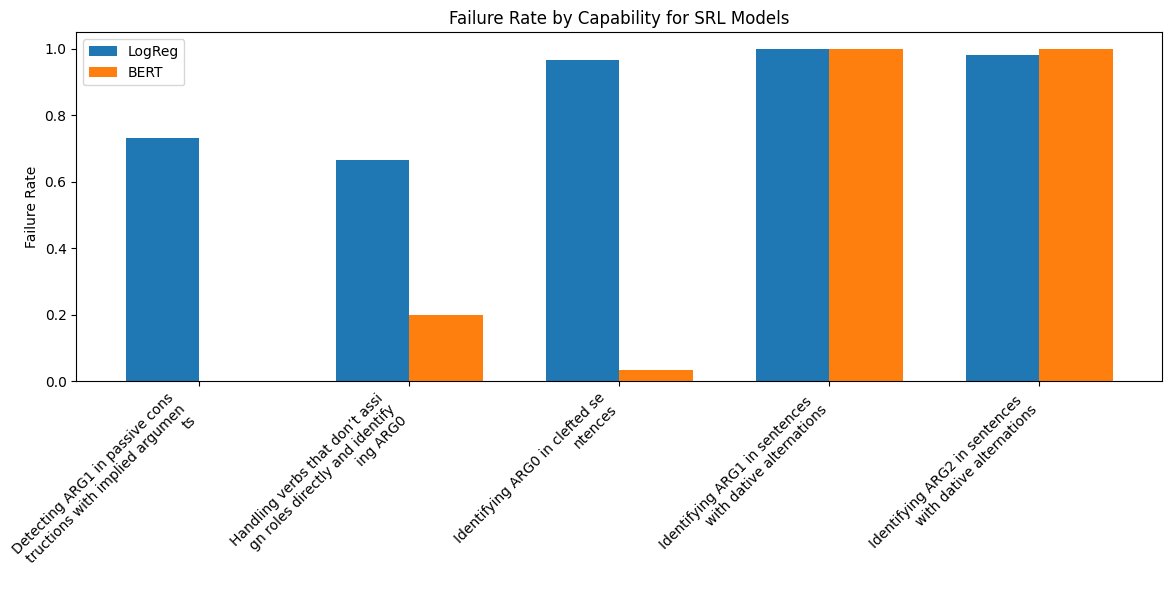

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("srl_failure_rates_by_capability.csv")
df['Capability'] = df['Capability'].apply(
    lambda x: '\n'.join(x[i:i+30] for i in range(0, len(x), 30)))

plt.figure(figsize=(12, 6))
x = range(len(df))
width = 0.35

plt.bar([i - width/2 for i in x], df['LogReg Failure Rate'],
        width=width, label='LogReg')
plt.bar([i + width/2 for i in x], df['BERT Failure Rate'],
        width=width, label='BERT')

plt.xticks(x, df['Capability'], rotation=45, ha='right')
plt.ylabel("Failure Rate")
plt.title("Failure Rate by Capability for SRL Models")
plt.legend()
plt.tight_layout()

plt.savefig("failure_rates.png", bbox_inches='tight', dpi=300)
plt.show()